# Homework 4 — Evaluation metrics

Evaluate the `converted` classifier from homework 3 with ROC AUC, precision, recall, F1 and 5-fold cross-validation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

df = pd.read_csv('course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Data preparation

Check missing values, then fill: categorical → `'NA'`, numerical → `0.0`.

In [2]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [3]:
target = 'converted'

# pandas 3 stores strings as the 'str' dtype, so select numbers instead of 'object'
numerical = [c for c in df.select_dtypes('number').columns if c != target]
categorical = [c for c in df.columns if c not in numerical and c != target]

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

print('categorical:', categorical)
print('numerical:', numerical)
df.isnull().sum().sum()

categorical: ['lead_source', 'industry', 'employment_status', 'location']
numerical: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


np.int64(0)

## Split the data

60/20/20 with the exact calls from the homework.

In [4]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

del df_train[target]
del df_val[target]
del df_test[target]

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

## Question 1 — ROC AUC feature importance

Use each numerical variable as the score and compute AUC against `y_train`. If AUC < 0.5, negate the variable.

In [5]:
for c in numerical:
    auc = roc_auc_score(y_train, df_train[c])
    inverted = ''
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
        inverted = ' (inverted)'
    print(f'{c}: {auc:.4f}{inverted}')

annual_income: 0.6082
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
lead_score: 0.7882


## Question 2 — AUC of the logistic regression model

In [6]:
features = categorical + numerical

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
X_val = dv.transform(df_val[features].to_dict(orient='records'))

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
round(roc_auc_score(y_val, y_pred), 3)

0.732

## Question 3 — precision and recall

Thresholds from 0.0 to 1.0 with step 0.01. The intersection is the threshold with the smallest |precision − recall|, ignoring thresholds where both are zero.

In [7]:
thresholds = np.arange(0.0, 1.01, 0.01)

rows = []
for t in thresholds:
    predict_positive = (y_pred >= t)
    actual_positive = (y_val == 1)

    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & ~actual_positive).sum()
    fn = (~predict_positive & actual_positive).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    rows.append((round(t, 2), precision, recall))

df_scores = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall'])
df_scores.head()

,threshold,precision,recall
0,0.00,0.586,1.0
1,0.01,0.586,1.0
2,0.02,0.586,1.0
3,0.03,0.586,1.0
4,0.04,0.586,1.0


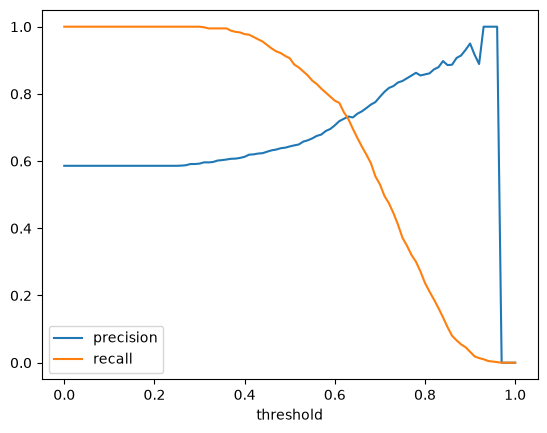

In [8]:
plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.xlabel('threshold')
plt.legend()
plt.show()

In [9]:
df_scores['diff'] = (df_scores.precision - df_scores.recall).abs()

candidates = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)]
candidates.loc[candidates['diff'].idxmin()]

threshold    0.630000
precision    0.732759
recall       0.725256
diff         0.007503
Name: 63, dtype: float64

## Question 4 — F1 score

$F_1 = 2 \cdot \dfrac{P \cdot R}{P + R}$

In [10]:
denominator = df_scores.precision + df_scores.recall
df_scores['f1'] = np.where(
    denominator > 0,
    2 * df_scores.precision * df_scores.recall / denominator.replace(0, np.nan),
    0.0,
)

df_scores.loc[df_scores.f1.idxmax()]

threshold    0.410000
precision    0.619048
recall       0.976109
diff         0.357062
f1           0.757616
Name: 41, dtype: float64

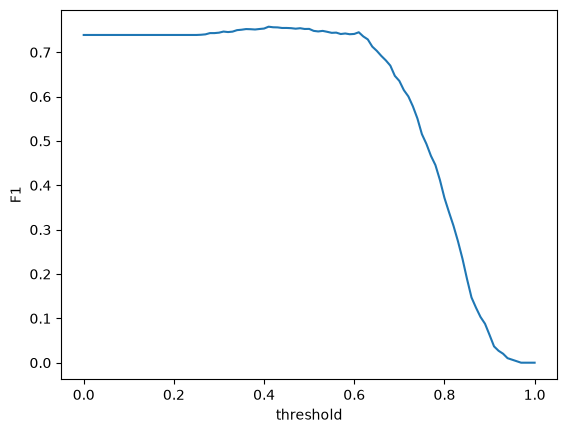

In [11]:
plt.plot(df_scores.threshold, df_scores.f1)
plt.xlabel('threshold')
plt.ylabel('F1')
plt.show()

## Question 5 — 5-fold cross-validation

In [12]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[features].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model


def predict(df, dv, model):
    dicts = df[features].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred


def cross_validate(C=1.0, n_splits=5):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        dv, model = train(df_tr, df_tr[target].values, C=C)
        y_pred = predict(df_va, dv, model)

        scores.append(roc_auc_score(df_va[target].values, y_pred))

    return scores

In [13]:
scores = cross_validate(C=1.0)
print(scores)
print('mean: %.3f, std: %.3f' % (np.mean(scores), np.std(scores)))

[0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
mean: 0.732, std: 0.007


## Question 6 — hyperparameter tuning with 5-fold CV

In [14]:
for C in [0.000001, 0.001, 1]:
    scores = cross_validate(C=C)
    print('C=%s: %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

C=1e-06: 0.617 +- 0.019


C=0.001: 0.749 +- 0.010


C=1: 0.732 +- 0.007


## Answers

| # | Question | Answer |
|---|----------|--------|
| 1 | Highest feature AUC | `lead_score` (0.788) |
| 2 | Model AUC on validation | 0.732 |
| 3 | Precision/recall intersection | 0.63 |
| 4 | Threshold with maximal F1 | 0.41 |
| 5 | 5-fold CV std | 0.007 |
| 6 | Best `C` | 0.001 (mean AUC 0.749) |